# EDA + Baseline — Churn Prediction (Etapa 1)

Tech Challenge Fase 1 (FIAP). Este notebook cobre o entregável da Etapa 1:
**análise exploratória de dados (volume, qualidade, distribuição das
features)** e o **baseline de Regressão Logística**.

Todo o carregamento, limpeza e pipeline de modelagem usam os mesmos módulos
de `src/churn/` consumidos pela API e pelo treino de produção
(`churn.train`) — não há lógica duplicada aqui. As decisões de quais
colunas descartar (vazamento, IDs, geográficas) já foram tomadas no
[ML Canvas](../docs/ml_canvas.md) (bloco 7) e estão centralizadas em
`churn.config`.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from churn import config, data, evaluate
from churn.models import get_candidates, BASELINE_NAME

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)


## 1. Volume e qualidade dos dados

Carregamos o dataset bruto (antes de qualquer limpeza) para avaliar volume,
tipos e valores ausentes tal como ele chega da fonte.


In [2]:
raw = data.load_raw()
print(f"Linhas: {raw.shape[0]} | Colunas: {raw.shape[1]}")
raw.dtypes.value_counts()


Linhas: 7043 | Colunas: 33


object     24
int64       6
float64     3
Name: count, dtype: int64

In [3]:
nulls = raw.isna().sum()
nulls[nulls > 0]


Churn Reason    5174
dtype: int64

`Total Charges` não aparece aqui como nulo porque vem como texto (`object`)
com 11 registros em branco — clientes com `tenure_months = 0` (contratos
recém-abertos, ainda sem fatura). `churn.data.clean` converte a coluna para
numérico e preenche esses casos com `0.0` (não a mediana da base), pois é o
valor correto para quem ainda não foi cobrado.


In [4]:
blank_total_charges = (raw["Total Charges"].astype(str).str.strip() == "").sum()
zero_tenure = (raw["Tenure Months"] == 0).sum()
print(f"'Total Charges' em branco: {blank_total_charges}")
print(f"Clientes com tenure_months = 0: {zero_tenure}")


'Total Charges' em branco: 11
Clientes com tenure_months = 0: 11


In [5]:
duplicated = raw.duplicated(subset=["CustomerID"]).sum()
print(f"CustomerIDs duplicados: {duplicated}")


CustomerIDs duplicados: 0


## 2. Dataset limpo (pós `churn.data.clean`)

Remove colunas de vazamento/ID/geográficas (`churn.config.DROP_COLS`),
renomeia para snake_case e corrige `total_charges`. É o dataset que
alimenta o baseline abaixo e os modelos comparados na Etapa 2.


In [6]:
df = data.load_clean()
print(f"Linhas: {df.shape[0]} | Colunas: {df.shape[1]}")
assert df.isna().sum().sum() == 0, "dataset limpo não deveria ter nulos"
df.head()


Linhas: 7043 | Colunas: 20


,gender,senior_citizen,partner,dependents,tenure_months,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn_value
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,1
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,1
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,1


## 3. Distribuição do alvo (`churn_value`)

Confirma o desbalanceamento de classes que motiva o uso de F1/AUC-PR em vez
de acurácia como métrica técnica (ver [`docs/metrics.md`](../docs/metrics.md)).


churn_value
não-churn    0.73463
churn        0.26537
Name: proportion, dtype: float64


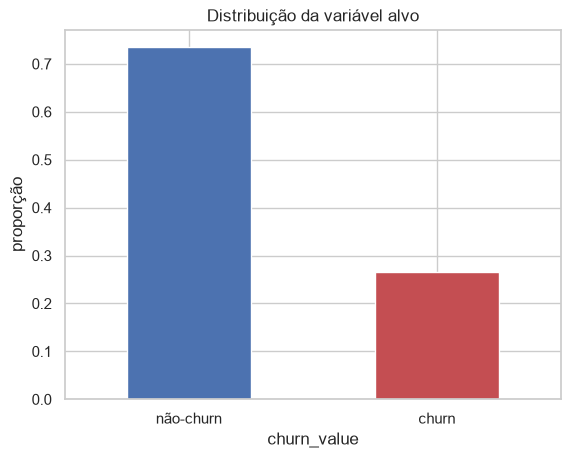

In [7]:
churn_rate = df["churn_value"].value_counts(normalize=True).rename({0: "não-churn", 1: "churn"})
print(churn_rate)

ax = churn_rate.plot(kind="bar", color=["#4C72B0", "#C44E52"])
ax.set_ylabel("proporção")
ax.set_title("Distribuição da variável alvo")
plt.xticks(rotation=0)
plt.show()


## 4. Features numéricas: `tenure_months`, `monthly_charges`, `total_charges`

Comparamos a distribuição de cada feature numérica entre clientes que
cancelaram e os que não cancelaram.


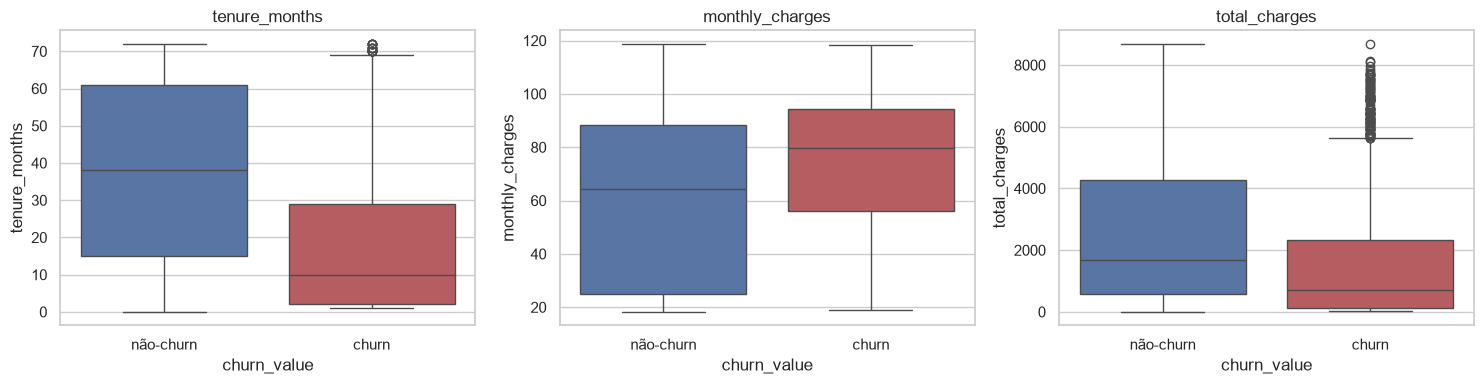

In [8]:
num_features = config.NUM_FEATURES

fig, axes = plt.subplots(1, len(num_features), figsize=(15, 4))
for ax, col in zip(axes, num_features):
    sns.boxplot(data=df, x="churn_value", y=col, ax=ax, hue="churn_value", legend=False,
                palette=["#4C72B0", "#C44E52"])
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["não-churn", "churn"])
    ax.set_title(col)
plt.tight_layout()
plt.show()


In [9]:
df.groupby("churn_value")[num_features].describe().T


churn_value                      0            1
tenure_months   count  5174.000000  1869.000000
                mean     37.569965    17.979133
                std      24.113777    19.531123
                min       0.000000     1.000000
                25%      15.000000     2.000000
                50%      38.000000    10.000000
                75%      61.000000    29.000000
                max      72.000000    72.000000
monthly_charges count  5174.000000  1869.000000
                mean     61.265124    74.441332
                std      31.092648    24.666053
                min      18.250000    18.850000
                25%      25.100000    56.150000
                50%      64.425000    79.650000
                75%      88.400000    94.200000
                max     118.750000   118.350000
total_charges   count  5174.000000  1869.000000
                mean   2549.911442  1531.796094
                std    2329.954215  1890.822994
                min       0.000000    18.850000
                25%     572.900000   134.500000
                50%    1679.525000   703.550000
                75%    4262.850000  2331.300000
                max    8672.450000  8684.800000

**Leitura:** clientes que cancelam têm tenure mediano bem menor (10 meses
vs. 38 meses dos que ficam) e `monthly_charges` tipicamente mais alto — ou
seja, o risco de churn se concentra em clientes novos pagando planos mais
caros.


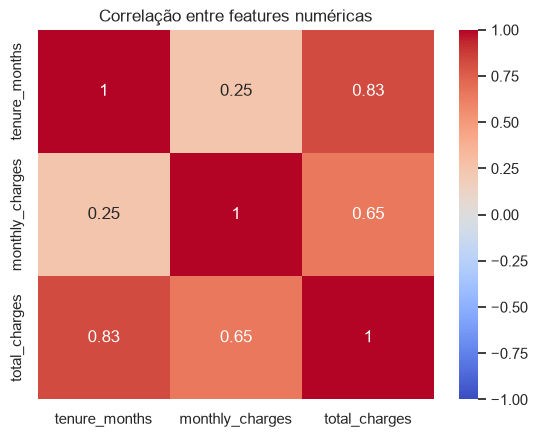

In [10]:
corr = df[num_features].corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlação entre features numéricas")
plt.show()


`total_charges` é fortemente correlacionada com `tenure_months` (≈0.83) —
esperado, já que é aproximadamente `tenure × monthly_charges` acumulado.
Nenhuma das três é redundante a ponto de justificar remoção nesta etapa;
fica registrado como um ponto de atenção para regularização/seleção de
features em modelos lineares.


## 5. Features categóricas: taxa de churn por categoria

Olhamos para as variáveis com maior separação aparente de risco:
`contract`, `internet_service` e `payment_method`.


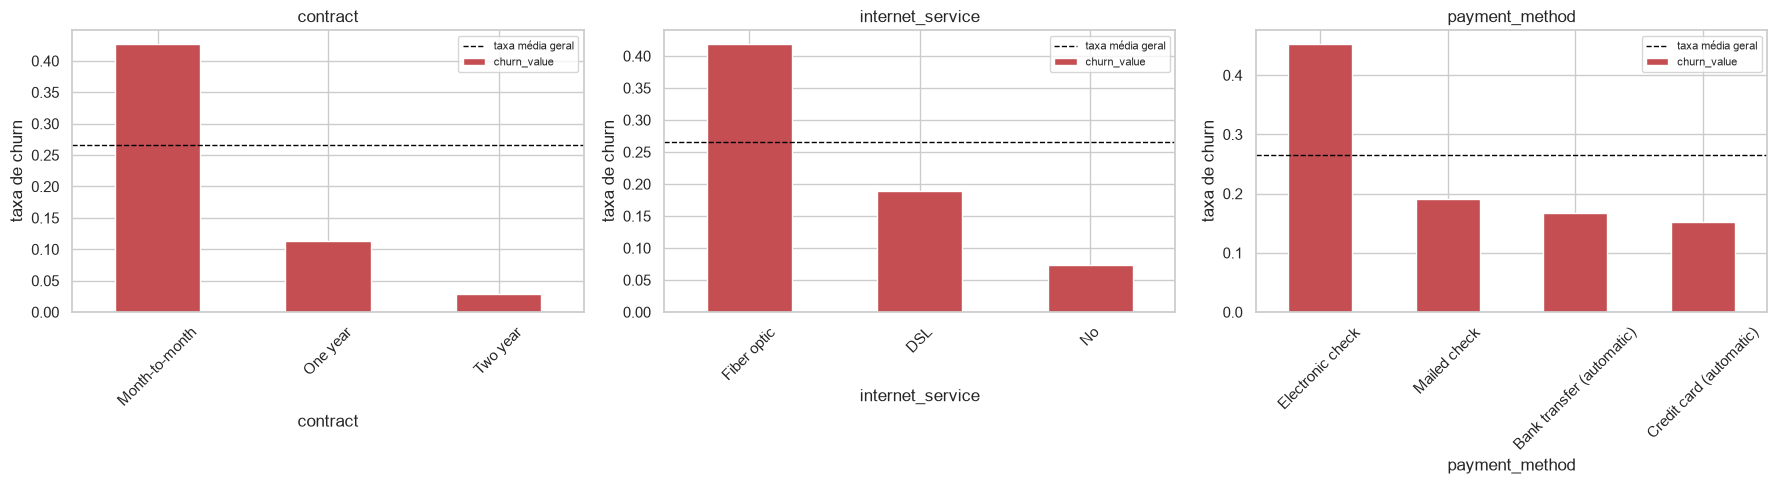

In [11]:
cat_cols_to_plot = ["contract", "internet_service", "payment_method"]

fig, axes = plt.subplots(1, len(cat_cols_to_plot), figsize=(18, 5))
for ax, col in zip(axes, cat_cols_to_plot):
    rate = df.groupby(col)["churn_value"].mean().sort_values(ascending=False)
    rate.plot(kind="bar", ax=ax, color="#C44E52")
    ax.axhline(df["churn_value"].mean(), color="black", linestyle="--", linewidth=1,
               label="taxa média geral")
    ax.set_ylabel("taxa de churn")
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=45)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


**Leitura:**

- **Contrato:** `Month-to-month` cancela a **42,7%**, contra 11,3% em
  contratos de 1 ano e apenas 2,8% em 2 anos — o sinal mais forte do
  dataset. Contratos de longo prazo são, por construção, uma barreira de
  saída.
- **Internet:** `Fiber optic` cancela a **41,9%**, quase o dobro de DSL
  (19,0%) e muito acima de quem não tem internet (7,4%) — compatível com
  reclamações de preço/qualidade do serviço de fibra, mas o dataset não
  documenta a causa, então isso fica como hipótese, não conclusão.
- **Pagamento:** `Electronic check` cancela a **45,3%**, bem acima dos
  demais métodos (todos entre 15% e 19%) — sugere um perfil de cliente
  menos "fidelizado" ao método de pagamento automático.

Essas três variáveis concentram boa parte do sinal preditivo do dataset e
devem dominar a importância de features nos modelos de árvore (Etapa 2).


## 6. Baseline — Regressão Logística

Treinamos o candidato `logistic_regression` do catálogo em
`churn.models.get_candidates()` — o mesmo Pipeline (pré-processamento +
estimador) usado no treino comparativo de produção (`churn.train`), sobre
o mesmo split estratificado (seed fixa em `churn.config.RANDOM_STATE`).
Isso garante que o baseline documentado aqui é exatamente comparável ao
que aparece em [`docs/model_comparison.csv`](../docs/model_comparison.csv).


In [12]:
X_train, X_test, y_train, y_test = data.split(df)

baseline = get_candidates()[BASELINE_NAME]
baseline.fit(X_train, y_train)

y_pred = baseline.predict(X_test)
y_proba = baseline.predict_proba(X_test)[:, 1]

baseline_metrics = evaluate.evaluate(y_test, y_pred, y_proba)
pd.Series(baseline_metrics, name=BASELINE_NAME).to_frame().T


,precision,recall,f1,roc_auc,pr_auc,precision_at_k
logistic_regression,0.51049,0.780749,0.617336,0.848854,0.645293,0.764286


## 7. Conclusões da Etapa 1

- Dataset com **7.043 clientes**, sem duplicados por `CustomerID`, sem
  nulos após a limpeza; o único tratamento necessário foi converter
  `total_charges` (11 registros em branco → clientes com tenure zero).
- Classes desbalanceadas (**73,5% não-churn / 26,5% churn**) — confirma a
  escolha de F1/AUC-PR como métrica técnica sobre acurácia
  (ver [`docs/metrics.md`](../docs/metrics.md)).
- Sinais mais fortes de risco: contrato `Month-to-month`, internet
  `Fiber optic`, pagamento por `Electronic check` e tenure baixo — todos
  na direção esperada pelo domínio de negócio (clientes recentes, sem
  barreira contratual, tendem a cancelar mais).
- Baseline de Regressão Logística estabelecido e avaliado nas mesmas
  métricas usadas para o modelo campeão. A comparação completa contra
  Random Forest e MLP (Etapa 2) está em
  [`docs/model_comparison.csv`](../docs/model_comparison.csv); o
  Random Forest venceu por F1-score e foi salvo como
  `models/champion.joblib`.
